# 02 · Dataset 2 — 과거 조건부·CUSUM 정보 8개 피처 (KODEX 200, 069500)

**이 노트북이 하는 일**

1. 01 노트북이 만든 클리닝 원천·급변 구간·정상 비교 구간을 읽고, 해시로 같은 입력인지 확인한다 (클리닝 결과는 수정하지 않는다).
2. 과거 정보만으로 계산되는 8개 피처를 만든다: 10일·120일 변동성, SVR–GARCH 예측분산, 세 가지 이동 CUSUM, Page 하방, X1 자기정규화 Page 하방.
3. **시범 계산 → 참조 구현과 비교 → 유사하면 등록, 아니면 기각**. 참조 값은 정답이 아니라 비교 기준선으로만 쓴다.
4. 급변 사건 날짜에 맞춰 정렬하고 가변 길이 학습 배열로 저장한다.

**알고리즘 정의**: 모든 정의를 이 노트북 안에 직접 구현했다 (외부 연구 모듈 import 없음). SVR–GARCH 는 Lee·Kim·Lee (2020) 방식을 따른다.

| 피처 | 컬럼 | 정의 요약 | 정보 시점 |
|---|---|---|---|
| 10일 변동성 | `volatility_10d` | 최근 10개 로그수익률 std(ddof=1)·√252 | t 종가 |
| 120일 변동성 | `volatility_120d` | 최근 120개, 같은 식 | t 종가 |
| SVR–GARCH 예측분산 | `predicted_variance` | 연초마다 그 전 자료로 적합한 SVR 이 (r²_{t−1}, σ̃²_{t−1}) 로 예측한 σ̂²_t | **t−1 종가** |
| 일반 CUSUM 60일 | `raw_cusum_60d` | 원수익률의 60일 이동 CUSUM-of-squares | t 종가 |
| SVR CUSUM 60일 | `svr_cusum_60d` | 표준화 잔차 e 의 60일 이동 CUSUM-of-squares | t 종가 |
| SVR CUSUM 120일 | `svr_cusum_120d` | e 의 120일 이동 CUSUM-of-squares | t 종가 |
| Page 하방 | `page_down` | 분산 감소(λ=0.5) 로그우도비 누적 상태 | t 종가 |
| X1 Page 하방 | `x1_page_down` | e 를 과거 [t−252, t−61] 잔차 척도로 나눈 뒤 같은 Page | t 종가 |

경보 여부·p값·vol20/vol60 및 그 비율은 입력에 넣지 않는다.

## 2. 실험 설정값

In [1]:
import os  # 환경 변수로 참조 파일 경로를 받기 위해
from pathlib import Path  # 경로 처리

ROOT = Path.cwd().parent  # 프로젝트 루트 (노트북은 notebooks/ 에서 실행)
TICKER = "069500"  # 종목코드 (문자열)
ANALYSIS_START, ANALYSIS_END = "2019-01-01", "2026-10-23"  # 분석 기간
FIRST_FIT_YEAR = 2018  # SVR 첫 적합 연도 — 2017 한 해를 학습 이력으로 쓰고 2018 을 워밍업으로 둔다
ANNUAL = 252  # 연환산 거래일 수
SEED = 20261024  # 고정 시드 (SVR 은 난수를 쓰지 않지만 기록용)
SVR_GRID_C = (1.0, 10.0, 100.0)  # SVR C 후보
SVR_GRID_G2 = (0.1, 0.5, 1.0)  # 원문 γ² 후보 (sklearn gamma = 1/(2γ²))
SVR_GRID_EPS = (0.1, 0.5, 1.0)  # SVR ε 후보
PROXY_M = 5  # 변동성 프록시 이동평균 길이 m
INNER_TRAIN_FRAC = 0.7  # 적합 이력 안에서 학습:검증 = 7:3
COS_MIN_VALID_FRAC = 0.9  # 이동 CUSUM 창의 최소 유효 비율
PAGE_LAMBDA_DOWN = 0.5  # Page 하방 분산비 λ
X1_LO, X1_HI, X1_MIN_VALID = 61, 252, 120  # X1 척도 창 [t−252, t−61], 최소 유효 120
GATE_CORR = 0.9  # 유사성 게이트 기준 (Pearson 상관)
GATE_PERIOD = ("2021-01-01", "2025-12-30")  # 기준선과 겹치는 비교 기간
BASELINE_LEDGER = Path(os.environ["D2_REFERENCE_FEATURES"]) if os.environ.get("D2_REFERENCE_FEATURES") else None  # 참조 구현의 일별 피처 (비공개 — 없으면 기록된 게이트 판정 사용)
FEATURES = ["volatility_10d", "volatility_120d", "predicted_variance", "raw_cusum_60d", "svr_cusum_60d", "svr_cusum_120d", "page_down", "x1_page_down"]  # 8개 피처 순서

PROC = ROOT / "data/processed/dataset_2"  # 원값 폴더
TRAIN = ROOT / "data/training/dataset_2"  # 학습 배열 폴더
QUALITY = ROOT / "data/quality"  # 품질 폴더
FIG = ROOT / "reports/figures"  # 그림 폴더
for d in (PROC, TRAIN, QUALITY, FIG):  # 폴더 생성
    d.mkdir(parents=True, exist_ok=True)  # 있으면 그대로

## 3. 필수 라이브러리 및 버전 확인

In [2]:
import hashlib  # 해시
import itertools  # 격자 탐색 후보 조합
import json  # 보고서 저장
import platform  # 파이썬 버전
import numpy as np  # 수치 계산
import pandas as pd  # 표 처리
import matplotlib  # 버전 확인
import matplotlib.pyplot as plt  # 그림
import sklearn  # 버전 확인
from numpy.lib.stride_tricks import sliding_window_view  # 이동창을 복사 없이 2차원 보기로 만든다
from sklearn.compose import TransformedTargetRegressor  # 목표값(y)도 표준화하는 래퍼 (원 정의: X·y 모두 표준화)
from sklearn.pipeline import Pipeline  # 표준화 → SVR 을 한 추정기로 묶는다
from sklearn.preprocessing import StandardScaler  # 평균 0·분산 1 표준화
from sklearn.svm import SVR  # 서포트 벡터 회귀

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}  # 버전 사전
plt.rcParams["font.family"] = ["NanumSquare", "Noto Sans CJK KR", "DejaVu Sans"]  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False  # 음수 부호 깨짐 방지
print(VERSIONS)  # 출력


def save_pair(df: pd.DataFrame, path: Path) -> None:
    """parquet 와 같은 이름의 csv 로 함께 저장."""
    df.to_parquet(path, index=False)  # parquet
    df.to_csv(path.with_suffix(".csv"), index=False)  # csv


def content_hash(df: pd.DataFrame) -> str:
    """표 내용 SHA-256 (인덱스 제외)."""
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=False).values.tobytes()).hexdigest()  # 행 해시 → 전체 해시


def save_json(obj: dict, path: Path) -> None:
    """한글 JSON 저장."""
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")  # 날짜 등은 문자열

{'python': '3.12.3', 'numpy': '2.4.6', 'pandas': '3.0.3', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.0'}


## 4. 입력 데이터 확인
01 노트북의 `_NB1_DONE.json` 에 적힌 내용 해시와 지금 읽은 파일의 해시가 같아야 한다. 다르면 다른 원천을 읽은 것이므로 멈춘다.

In [3]:
done = json.loads((ROOT / "data/events/_NB1_DONE.json").read_text(encoding="utf-8"))  # 01 노트북 완료 기록
clean = pd.read_parquet(ROOT / done["clean"]["path"])  # 클리닝 원천
ev = pd.read_parquet(ROOT / done["events"]["path"])  # 급변 구간
nref = pd.read_parquet(ROOT / done["normal_windows"]["path"])  # 정상 비교 구간
for key, tab in (("clean", clean), ("events", ev), ("normal_windows", nref)):  # 세 입력마다
    assert content_hash(tab) == done[key]["content_hash"], f"{key} 해시 불일치 — 01 노트북 결과와 다른 입력"  # 입력 동일성 확인
assert list(clean.columns) == ["ticker", "date", "open", "high", "low", "close", "volume", "change_source", "is_warmup"], "클리닝 스키마 불일치"  # 스키마 확인
print("입력 해시 일치 | 원천 SHA-256:", done["raw_sha256"][:16], "| 행:", len(clean), "| 사건:", len(ev))  # 확인 결과

입력 해시 일치 | 원천 SHA-256: 264b1629b7928c1b | 행: 2403 | 사건: 80


## 5. 공통 원천 로딩
이 노트북은 수집하지 않는다. 클리닝된 종가에서 두 가지 수익률을 만든다.
- `lr` = ln(close_t/close_{t−1}) (소수) — 변동성 피처용
- `r_pct` = 100·lr (퍼센트) — SVR–GARCH·CUSUM 용 (원 연구와 같은 단위)

In [4]:
px = clean[["date", "close"]].copy()  # 날짜·종가
px["lr"] = np.log(px["close"]).diff()  # 로그수익률 (첫날 결측)
px["r_pct"] = 100.0 * px["lr"]  # 퍼센트 로그수익률
px = px.iloc[1:].reset_index(drop=True)  # 첫날(수익률 없음) 제외 — 2017-01-03 부터
r = px["r_pct"].to_numpy()  # 수익률 배열 (모형 입력)
years = px["date"].dt.year.to_numpy()  # 연도 배열
print(px["date"].iloc[0].date(), "~", px["date"].iloc[-1].date(), "| 수익률", len(px), "개, 결측", int(np.isnan(r).sum()))  # 범위

2017-01-03 ~ 2026-10-23 | 수익률 2402 개, 결측 0


## 6. 클리닝 결과 확인
클리닝은 01 노트북의 책임이다. 여기서는 수익률 계산에 필요한 조건(종가 양수, 결측 없음)만 다시 확인한다.

In [5]:
assert (clean["close"] > 0).all() and clean["close"].notna().all(), "종가 조건 위반"  # 로그 계산 가능 조건
assert not np.isnan(r).any(), "수익률 결측"  # SVR 학습 입력은 유한해야 한다
print("클리닝 조건 확인 완료")  # 통과

클리닝 조건 확인 완료


## 7. 피처 정제
### 7-1. 10일·120일 연환산 변동성
정확히 10개·120개의 로그수익률이 있을 때만 계산한다 (`min_periods` = 창 길이).

In [6]:
daily = px[["date"]].copy()  # 일별 피처 표
daily["volatility_10d"] = px["lr"].rolling(10, min_periods=10).std(ddof=1) * np.sqrt(ANNUAL)  # 10일 변동성
daily["volatility_120d"] = px["lr"].rolling(120, min_periods=120).std(ddof=1) * np.sqrt(ANNUAL)  # 120일 변동성

### 7-2. SVR–GARCH 예측분산 (연간 확장 재적합)
Lee·Kim·Lee (2020) 방식의 규칙:

1. **프록시** σ̃²_t = 최근 m=5 개 r² 의 평균 (t 포함, 앞쪽은 있는 만큼).
2. **특징·목표**: 특징 (r²_{t−1}, σ̃²_{t−1}) → 목표 σ̃²_t.
3. **적합**: 매년 첫 거래일 Y 에, Y 이전의 모든 수익률을 이력으로 앞 70% 학습·뒤 30% 검증. 27개 (C, γ², ε) 후보 중 검증 MAE 가 가장 작은 것(같으면 먼저 나온 것) 선택 → 이력 전체로 다시 적합.
   학습 블록의 프록시는 학습 블록 안에서만, 검증 블록의 프록시는 학습 블록에 이어서 계산한다.
4. **추정기**: X 표준화 → RBF SVR, 목표 y 도 표준화 (`TransformedTargetRegressor`). γ_sklearn = 1/(2γ²).
5. **예측**: 그 해의 날 t 마다 실제 관측된 r²_{t−1}·σ̃²_{t−1} 를 넣는다 (관측 프록시 사용). 따라서 σ̂²_t 는 **t−1 종가까지의 정보**로 계산된다.
6. 예측값이 0 이하면 표준화 잔차 e 는 결측 (예측분산 자체는 원값 그대로 저장).

In [7]:
GRID = list(itertools.product(SVR_GRID_C, SVR_GRID_G2, SVR_GRID_EPS))  # 27개 후보 (C, γ², ε) — 순서가 동점 처리 규칙


def proxy(x: np.ndarray, m: int = PROXY_M) -> np.ndarray:
    """σ̃²_t = 최근 ≤m 개 x² 평균 (t 포함)."""
    return pd.Series(x ** 2).rolling(m, min_periods=1).mean().to_numpy()  # 앞쪽은 있는 개수로 평균 (원 정의의 확장 평균)


def make_estimator(C: float, g2: float, eps: float) -> TransformedTargetRegressor:
    """X·y 표준화 + RBF SVR 추정기."""
    svr = SVR(kernel="rbf", C=C, gamma=1.0 / (2.0 * g2), epsilon=eps)  # 원문 γ² 를 sklearn gamma 로 변환
    return TransformedTargetRegressor(regressor=Pipeline([("x_scaler", StandardScaler()), ("svr", svr)]), transformer=StandardScaler())  # y 도 표준화


def fit_svr(h: np.ndarray):
    """이력 h 로 격자 선택 후 전체 재적합. (모형, 선택 후보, 검증 MAE, 학습 크기) 반환."""
    n = round(INNER_TRAIN_FRAC * len(h))  # 내부 학습 크기
    tr = h[:n]  # 내부 학습 블록
    p_tr = proxy(tr)  # 학습 블록 프록시 (학습 블록 안에서만)
    p_all = proxy(h)  # 이어서 계산한 프록시 (검증 블록용)
    Xt, yt = np.c_[tr[:-1] ** 2, p_tr[:-1]], p_tr[1:]  # 학습 특징·목표
    Xv, yv = np.c_[h[n - 1:-1] ** 2, p_all[n - 1:-1]], p_all[n:]  # 검증 특징(직전 학습 블록 끝 포함)·목표
    maes = [float(np.mean(np.abs(make_estimator(*g).fit(Xt, yt).predict(Xv) - yv))) for g in GRID]  # 후보별 검증 MAE
    best = GRID[int(np.argmin(maes))]  # 최소 MAE (동점이면 argmin 이 첫 후보)
    model = make_estimator(*best).fit(np.c_[h[:-1] ** 2, p_all[:-1]], p_all[1:])  # 이력 전체로 재적합
    return model, best, min(maes), n  # 결과


vhat = np.full(len(r), np.nan)  # 예측분산 배열
fit_id = np.full(len(r), -1)  # 날짜별 사용한 적합 번호
fits = []  # 적합 기록
starts = [int(np.flatnonzero(years == y)[0]) for y in range(FIRST_FIT_YEAR, int(years.max()) + 1)]  # 연도별 첫 거래일 위치
for k, a in enumerate(starts):  # 연도마다
    b = starts[k + 1] if k + 1 < len(starts) else len(r)  # 그 해 마지막 다음 위치
    model, best, mae, n_tr = fit_svr(r[:a])  # a 이전 자료만으로 적합 (미래 자료 없음)
    pc = proxy(r[:b])  # 그 해 끝까지 이어진 관측 프록시 (t−1 값만 사용됨)
    vhat[a:b] = model.predict(np.c_[r[a - 1:b - 1] ** 2, pc[a - 1:b - 1]])  # 날 t 예측 = (r²_{t−1}, σ̃²_{t−1}) 입력
    fit_id[a:b] = k  # 적합 번호 기록
    fits.append({"model_fit_id": k, "fit_at": px["date"].iloc[a].date(), "train_start": px["date"].iloc[0].date(), "train_end": px["date"].iloc[a - 1].date(), "n_history": a, "n_inner_train": n_tr, "C": best[0], "gamma2": best[1], "epsilon": best[2], "val_mae": round(mae, 6), "predict_from": px["date"].iloc[a].date(), "predict_to": px["date"].iloc[b - 1].date()})  # 기록
fits = pd.DataFrame(fits)  # 적합 기록 표
e = np.where(vhat > 0, r / np.sqrt(np.where(vhat > 0, vhat, 1.0)), np.nan)  # 표준화 잔차 e = r/√σ̂² (σ̂²≤0 → 결측)
daily["predicted_variance"] = vhat  # 피처 저장 (%² 단위)
daily["model_fit_id"] = fit_id  # 메타 (입력 아님)
first_pos = np.r_[[np.flatnonzero(fit_id == k)[0] if (fit_id == k).any() else -1 for k in range(len(starts))]]  # 적합별 첫 위치
daily["days_since_refit"] = np.where(fit_id >= 0, np.arange(len(r)) - first_pos[np.clip(fit_id, 0, None)], -1)  # 재적합 후 경과일 (메타)
rep = pd.Series(vhat).groupby([fit_id, np.round(vhat, 9)]).transform("size")  # 같은 적합 안 같은 값 반복 횟수
daily["forecast_ceiling"] = (fit_id >= 0) & (rep.to_numpy() >= 5)  # 같은 값 5회 이상 반복 = 예측 상수 고정 표시 (메타 — 학습 입력 아님)
save_pair(fits, PROC / "svr_fit_log.parquet")  # 적합 기록 저장
print("v̂ ≤ 0 인 날:", int((vhat <= 0).sum()), "| 상수 고정 표시 날:", int(daily["forecast_ceiling"].sum()))  # 요약
fits  # 적합 기록

v̂ ≤ 0 인 날: 2 | 상수 고정 표시 날: 38


,model_fit_id,fit_at,train_start,train_end,n_history,n_inner_train,C,gamma2,epsilon,val_mae,predict_from,predict_to
0,0,2018-01-02,2017-01-03,2017-12-28,242,169,10.0,0.5,0.1,0.138727,2018-01-02,2018-12-28
1,1,2019-01-02,2017-01-03,2018-12-28,486,340,1.0,1.0,0.1,0.317840,2019-01-02,2019-12-30
2,2,2020-01-02,2017-01-03,2019-12-30,732,512,10.0,1.0,0.1,0.191640,2020-01-02,2020-12-30
3,3,2021-01-04,2017-01-03,2020-12-30,980,686,1.0,1.0,0.1,1.869670,2021-01-04,2021-12-30
4,4,2022-01-03,2017-01-03,2021-12-30,1228,860,10.0,1.0,0.1,0.330415,2022-01-03,2022-12-29
5,5,2023-01-02,2017-01-03,2022-12-29,1474,1032,10.0,0.5,0.1,0.301917,2023-01-02,2023-12-28
6,6,2024-01-02,2017-01-03,2023-12-28,1719,1203,10.0,1.0,0.1,0.324709,2024-01-02,2024-12-30
7,7,2025-01-02,2017-01-03,2024-12-30,1963,1374,10.0,1.0,0.1,0.415469,2025-01-02,2025-12-30
8,8,2026-01-02,2017-01-03,2025-12-30,2205,1544,10.0,1.0,0.1,0.518873,2026-01-02,2026-10-23


### 7-3. 이동 CUSUM-of-squares (일반 60일, SVR 60일, SVR 120일)
시점 t 의 창 [t−w+1, t] 에서 유효 값 x 만 써서

T_t(w) = max_k |S_k − (k/n)·S_n| / (√n · τ̂),  S_k = Σ_{s≤k} x_s²,  τ̂² = mean(x⁴) − mean(x²)²

유효 값이 ⌈0.9w⌉ 개 미만이거나 τ̂² ≤ 0 이면 결측. 결측 값은 건너뛴 것과 같게 처리한다 (유효 개수 k 를 누적).
일반 CUSUM 은 원수익률 `r_pct`, SVR CUSUM 은 표준화 잔차 `e` 에 적용한다. 60일과 120일은 별개 통계량이다.

In [8]:
def rolling_cos(x: np.ndarray, w: int) -> np.ndarray:
    """창 [t−w+1, t] 의 CUSUM-of-squares 통계량 (앞 w−1 개 결측)."""
    out = np.full(len(x), np.nan)  # 결과 배열
    W = sliding_window_view(x, w)  # (창 수, w) 보기 — 각 행이 한 시점의 창
    valid = ~np.isnan(W)  # 유효 위치
    sq = np.where(valid, W, 0.0) ** 2  # 결측은 0 으로 두고 제곱 (누적합에서 건너뜀)
    n = valid.sum(axis=1)  # 창별 유효 개수
    k = np.cumsum(valid, axis=1)  # 유효 개수 누적
    s = np.cumsum(sq, axis=1)  # 제곱합 누적 S_k
    with np.errstate(invalid="ignore", divide="ignore"):  # 0 나누기 경고는 아래에서 결측 처리
        path = s - k / n[:, None] * s[:, -1:]  # S_k − (k/n)S_n
        tau2 = (np.where(valid, W, 0.0) ** 4).sum(axis=1) / n - (s[:, -1] / n) ** 2  # τ̂²
        peak = np.where(valid, np.abs(path), -np.inf).max(axis=1)  # 유효 위치에서만 최대
        stat = peak / (np.sqrt(n) * np.sqrt(tau2))  # 통계량
    stat[(n < int(np.ceil(COS_MIN_VALID_FRAC * w))) | ~(tau2 > 0)] = np.nan  # 유효 부족·τ̂² 비양수 → 결측
    out[w - 1:] = stat  # 창 끝 시점에 기록
    return out  # 결과


daily["raw_cusum_60d"] = rolling_cos(r, 60)  # 일반 CUSUM 60일 (원수익률)
daily["svr_cusum_60d"] = rolling_cos(e, 60)  # SVR CUSUM 60일
daily["svr_cusum_120d"] = rolling_cos(e, 120)  # SVR CUSUM 120일
for w in (60, 120):  # 창이 재적합 경계를 포함하는지 (모형 혼합 창 — 메타)
    daily[f"cos{w}_mixed_fit"] = pd.Series(fit_id).rolling(w, min_periods=1).apply(lambda v: len(set(v)) > 1, raw=True).astype(bool).to_numpy()  # 창 안 적합 번호가 둘 이상이면 True

### 7-4. Page 하방 · X1 자기정규화 Page 하방
- 증분 `inc_t = 0.5·((1 − 1/λ)·e_t² − ln λ)`, λ = 0.5 (분산이 절반으로 줄었다는 가설의 정규 로그우도비).
- 상태 `S_t = max(0, S_{t−1} + inc_t)`. e 가 결측이면 상태를 그대로 유지한다. 경보 후 재설정은 하지 않는다 (연속 통계량). 첫 유효 e 에서 0 으로 시작한다.
- **X1**: e_t 를 과거 척도 √m_t 로 나눈다. m_t = 위치 [t−252, t−61] 의 유효 e² 평균 (t 와 가까운 60일은 제외). 유효가 120개 미만이면 결측. 이렇게 나눈 값에 같은 Page 를 적용한다.

In [9]:
def page_free(x: np.ndarray, lam: float) -> np.ndarray:
    """경보 후 재설정 없는 Page 상태 경로 (첫 유효 값 이전은 결측)."""
    inc = 0.5 * ((1.0 - 1.0 / lam) * x ** 2 - np.log(lam))  # 로그우도비 증분
    S = np.full(len(x), np.nan)  # 상태 배열
    s, seen = 0.0, False  # 현재 상태, 유효 값을 본 적이 있는지
    for t in range(len(x)):  # 시간순 (상태가 앞 값에 의존하므로 반복문)
        if np.isfinite(inc[t]):  # 유효한 날만 갱신
            s = max(0.0, s + inc[t])  # 0 아래로 내려가지 않는 누적
            seen = True  # 시작 표시
        if seen:  # 시작 이후에는
            S[t] = s  # 상태 기록 (결측 날은 직전 상태 유지)
    return S  # 결과


def selfnorm(x: np.ndarray, lo: int = X1_LO, hi: int = X1_HI, min_valid: int = X1_MIN_VALID) -> np.ndarray:
    """x_t / √(위치 [t−hi, t−lo] 유효 x² 평균), 유효 < min_valid → 결측."""
    sq = np.where(np.isfinite(x), x ** 2, 0.0)  # 결측은 0 (합에서 제외)
    ok = np.isfinite(x).astype(float)  # 유효 표시
    cs = np.r_[0.0, np.cumsum(sq)]  # 제곱 누적합 (앞에 0)
    cn = np.r_[0.0, np.cumsum(ok)]  # 유효 개수 누적합
    t = np.arange(len(x))  # 위치
    a = np.clip(t - hi, 0, len(x))  # 창 시작 위치 t−252
    b = np.clip(t - lo + 1, 0, len(x))  # 창 끝 다음 위치 (t−61 포함)
    s, c = cs[b] - cs[a], cn[b] - cn[a]  # 창 합과 개수
    with np.errstate(invalid="ignore", divide="ignore"):  # 0 나누기는 결측 처리
        m = np.where(c >= min_valid, s / c, np.nan)  # 과거 척도
        return x / np.sqrt(m)  # 자기정규화 값


daily["page_down"] = page_free(e, PAGE_LAMBDA_DOWN)  # Page 하방
e_sn = selfnorm(e)  # X1 자기정규화 잔차
daily["x1_page_down"] = page_free(e_sn, PAGE_LAMBDA_DOWN)  # X1 Page 하방
daily["e_std_residual"] = e  # 표준화 잔차 (메타 — 입력 아님)
daily["r_pct"] = r  # 퍼센트 수익률 (메타 — 입력 아님)
print(daily[FEATURES].notna().sum().to_dict())  # 피처별 유효 개수

{'volatility_10d': 2393, 'volatility_120d': 2283, 'predicted_variance': 2160, 'raw_cusum_60d': 2343, 'svr_cusum_60d': 2107, 'svr_cusum_120d': 2053, 'page_down': 2160, 'x1_page_down': 1980}


### 7-5. 유사성 게이트 — 참조 구현과 비교
시범 계산 값이 독립적으로 구현된 참조 계산(같은 정의, 비공개 일별 피처 파일)과 비슷하면 등록하고, 아니면 기각한다.
참조 계산은 SVR 학습 이력을 2019-01-03 부터 썼고 여기서는 2017-01-03 부터 쓰므로 **값이 정확히 같을 수는 없다**. 그래서 같은 정의가 같은 움직임을 만드는지를 겹치는 기간(2021–2025) Pearson 상관 ≥ 0.9 로 판단한다.
참고로 참조 설정(2019 이력·2020 첫 적합) 그대로 이 노트북의 SVR 정의를 돌리면 참조 v̂ 와 최대 절대차 0.003 (%²) 이었다.
10·120일 변동성은 참조 파일에 없으므로 12절 재계산 검증으로 대신한다.

**참조 파일이 없을 때** (공개 저장소에서 다시 실행하는 경우): 환경 변수 `D2_REFERENCE_FEATURES` 로 경로를 주지 않으면, 아래 `RECORDED_GATE` 에 적어 둔 최초 실행의 게이트 결과를 그대로 적용한다. 등록·기각 판정이 같으므로 학습 배열도 같다.

In [10]:
GATE_MAP = {  # 피처 → (참조 실험 ID, 참조 컬럼, 창 길이 필터)
    "predicted_variance": ("B1", "predicted_variance", "60"),
    "svr_cusum_60d": ("B1", "cusum_raw_T", "60"),
    "svr_cusum_120d": ("E2_w120", "cusum_raw_T", "120"),
    "raw_cusum_60d": ("E3_raw_rolling_cos", "cusum_raw_T", "60"),
    "page_down": ("E3_page_down", "cusum_raw_T", None),
    "x1_page_down": ("X1_page_down_sn", "cusum_raw_T", None),
}
RECORDED_GATE = {  # 최초 실행(참조 파일 사용)의 게이트 결과 — 참조 파일이 없을 때 그대로 적용
    "predicted_variance": (1473, 1225, 0.9643, 0.050654, "REGISTERED"),
    "svr_cusum_60d": (1473, 1225, 0.9563, 0.029829, "REGISTERED"),
    "svr_cusum_120d": (1473, 1225, 0.9381, 0.030146, "REGISTERED"),
    "raw_cusum_60d": (1473, 1225, 1.0, 0.0, "REGISTERED"),
    "page_down": (1473, 1225, 0.8131, 0.004893, "REJECTED"),
    "x1_page_down": (1473, 1225, 0.9752, 0.05114, "REGISTERED"),
}
gate_rows = []  # 게이트 결과 리스트
if BASELINE_LEDGER is not None and BASELINE_LEDGER.exists():  # 참조 파일이 있을 때만 직접 비교
    led = pd.read_parquet(BASELINE_LEDGER, columns=["date", "experiment_id", "window_w", "reset_rule", "predicted_variance", "cusum_raw_T"])  # 필요한 컬럼만 읽기
    mine = daily.set_index("date")  # 날짜 인덱스
    for f, (eid, col, w) in GATE_MAP.items():  # 피처마다
        sub = led[(led["experiment_id"] == eid) & (led["reset_rule"] == "none")]  # 실험·초기화 없음 필터
        if w is not None:  # 창 길이 필터
            sub = sub[sub["window_w"].astype(str) == w]  # 같은 창
        base = sub.drop_duplicates("date").set_index("date")[col]  # 날짜별 참조 값
        both = pd.concat([mine[f], base], axis=1, keys=["new", "base"]).loc[GATE_PERIOD[0]:GATE_PERIOD[1]].dropna()  # 겹치는 유효 날짜
        corr = float(both["new"].corr(both["base"])) if len(both) > 30 else np.nan  # Pearson 상관
        gate_rows.append({"feature": f, "baseline_experiment": eid, "baseline_rows": int(len(sub)), "overlap_days": int(len(both)), "pearson_corr": round(corr, 4), "median_abs_diff": round(float((both["new"] - both["base"]).abs().median()), 6) if len(both) else np.nan, "decision": "REGISTERED" if corr >= GATE_CORR else "REJECTED"})  # 판정
    for row in gate_rows:  # 직접 계산한 판정이 기록값과 같은지 확인
        assert row["decision"] == RECORDED_GATE[row["feature"]][4], f"게이트 판정이 기록값과 다르다: {row}"  # 다르면 기록값을 고쳐야 한다
    GATE_SOURCE = "computed"  # 판정 출처
else:  # 참조 파일이 없으면 기록된 판정을 적용
    for f, (eid, col, w) in GATE_MAP.items():  # 피처마다
        n_rows, n_overlap, corr, mad, dec = RECORDED_GATE[f]  # 기록값 풀기
        gate_rows.append({"feature": f, "baseline_experiment": eid, "baseline_rows": n_rows, "overlap_days": n_overlap, "pearson_corr": corr, "median_abs_diff": mad, "decision": dec})  # 기록값 그대로
    GATE_SOURCE = "recorded"  # 판정 출처
gate = pd.DataFrame(gate_rows)  # 게이트 표
for f in ("volatility_10d", "volatility_120d"):  # 참조 값이 없는 두 피처
    gate.loc[len(gate)] = {"feature": f, "baseline_experiment": "none (정의 재계산 검증)", "baseline_rows": 0, "overlap_days": 0, "pearson_corr": np.nan, "median_abs_diff": np.nan, "decision": "REGISTERED"}  # 재계산 검증으로 등록
save_pair(gate, QUALITY / "dataset_2_similarity_gate.parquet")  # 저장
REGISTERED = [f for f in FEATURES if gate.set_index("feature").loc[f, "decision"] == "REGISTERED"]  # 등록된 피처 (원래 순서 유지)
REJECTED = [f for f in FEATURES if f not in REGISTERED]  # 기각된 피처
print("게이트 판정 출처:", GATE_SOURCE, "| 등록:", REGISTERED, "| 기각:", REJECTED)  # 결과
gate  # 게이트 표

게이트 판정 출처: computed | 등록: ['volatility_10d', 'volatility_120d', 'predicted_variance', 'raw_cusum_60d', 'svr_cusum_60d', 'svr_cusum_120d', 'x1_page_down'] | 기각: ['page_down']


,feature,baseline_experiment,baseline_rows,overlap_days,pearson_corr,median_abs_diff,decision
0,predicted_variance,B1,1473,1225,0.9643,0.050654,REGISTERED
1,svr_cusum_60d,B1,1473,1225,0.9563,0.029829,REGISTERED
2,svr_cusum_120d,E2_w120,1473,1225,0.9381,0.030146,REGISTERED
3,raw_cusum_60d,E3_raw_rolling_cos,1473,1225,1.0000,0.000000,REGISTERED
4,page_down,E3_page_down,1473,1225,0.8131,0.004893,REJECTED
5,x1_page_down,X1_page_down_sn,1473,1225,0.9752,0.051140,REGISTERED
6,volatility_10d,none (정의 재계산 검증),0,0,NaN,NaN,REGISTERED
7,volatility_120d,none (정의 재계산 검증),0,0,NaN,NaN,REGISTERED


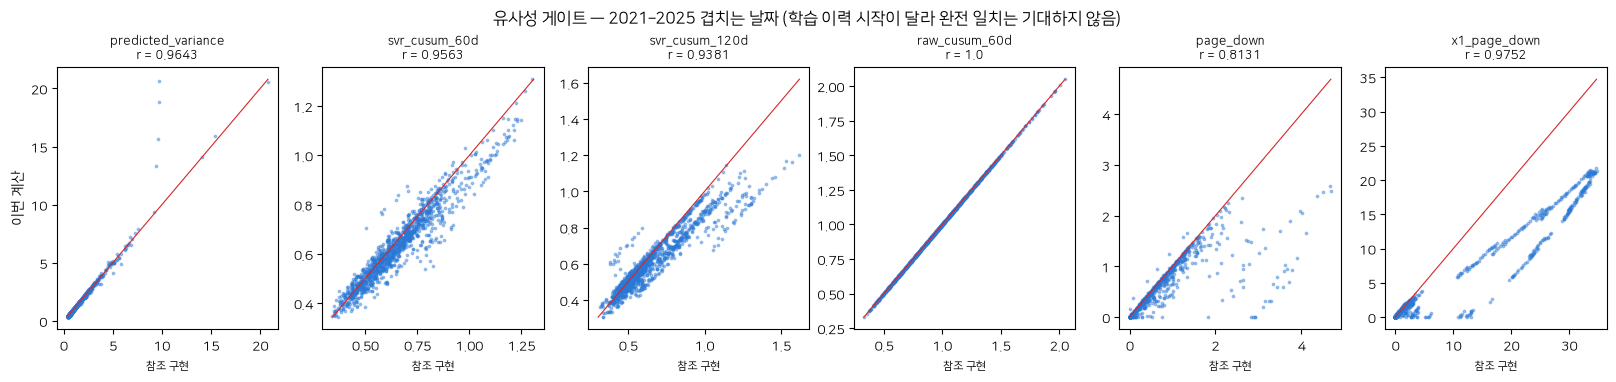

In [11]:
if GATE_SOURCE == "computed":  # 참조 파일이 있을 때만 산점도
    fig, axes = plt.subplots(1, 6, figsize=(20, 3.4))  # 6개 비교
    for ax, (f, (eid, col, w)) in zip(axes, GATE_MAP.items()):  # 피처마다
        sub = led[(led["experiment_id"] == eid) & (led["reset_rule"] == "none")]  # 같은 필터
        sub = sub[sub["window_w"].astype(str) == w] if w else sub  # 창 필터
        both = pd.concat([mine[f], sub.drop_duplicates("date").set_index("date")[col]], axis=1, keys=["new", "base"]).loc[GATE_PERIOD[0]:GATE_PERIOD[1]].dropna()  # 겹치는 날
        ax.scatter(both["base"], both["new"], s=3, alpha=0.4, color="#2a78d6")  # 산점도
        lim = [np.nanmin(both.values), np.nanmax(both.values)]  # 대각선 범위
        ax.plot(lim, lim, color="#d62728", lw=0.8)  # y = x
        ax.set_title(f"{f}\nr = {gate.set_index('feature').loc[f, 'pearson_corr']}", fontsize=9)  # 제목
        ax.set_xlabel("참조 구현", fontsize=8)  # 축
    axes[0].set_ylabel("이번 계산")  # 축
    fig.suptitle("유사성 게이트 — 2021–2025 겹치는 날짜 (학습 이력 시작이 달라 완전 일치는 기대하지 않음)", y=1.05)  # 제목
    fig.savefig(FIG / "02_similarity_gate.png", dpi=130, bbox_inches="tight")  # 저장
    plt.show()  # 표시

## 8. 이벤트·날짜 정렬
01 노트북의 표본 사건(`in_main_sample`)과 정상 구간 날짜에 맞춰 일별 피처를 꺼낸다. Dataset 1 과 같은 event_id·날짜·day_index 여야 한다.

In [12]:
save_pair(daily, PROC / "daily_features.parquet")  # 전체 일별 피처 + 메타 저장
main_ev = ev[ev["in_main_sample"]].sort_values("event_id").reset_index(drop=True)  # 표본 사건
META = ["model_fit_id", "days_since_refit", "forecast_ceiling", "cos60_mixed_fit", "cos120_mixed_fit"]  # 함께 넘기는 메타 (입력 아님)


def expand(windows: pd.DataFrame, id_col: str, extra: list) -> pd.DataFrame:
    """구간 → 하루 행 + 피처·메타."""
    parts = []  # 구간별 표
    for w in windows.itertuples(index=False):  # 구간마다
        part = daily[(daily["date"] >= w.start_date) & (daily["date"] <= w.end_date)].copy()  # 구간 날짜
        part.insert(0, id_col, getattr(w, id_col))  # 구간 ID
        for c in extra:  # 추가 식별
            part.insert(1, c, getattr(w, c))  # 컬럼 추가
        part.insert(2 + len(extra), "ticker", TICKER)  # 종목
        part["day_index"] = np.arange(1, len(part) + 1)  # 순번
        parts.append(part)  # 추가
    return pd.concat(parts, ignore_index=True)  # 합치기


rows = expand(main_ev, "event_id", [])[["event_id", "ticker", "date", "day_index"] + FEATURES + META]  # 사건 행
save_pair(rows, PROC / "event_rows.parquet")  # 저장
nrows = expand(nref[nref["matched"]], "ref_id", ["matched_event_id"])[["ref_id", "matched_event_id", "ticker", "date", "day_index"] + FEATURES + META]  # 정상 구간 행
save_pair(nrows, PROC / "normal_reference.parquet")  # 저장
d1 = ROOT / "data/processed/dataset_1/event_rows.parquet"  # Dataset 1 사건 행
same_as_d1 = d1.exists() and pd.read_parquet(d1)[["event_id", "date", "day_index"]].equals(rows[["event_id", "date", "day_index"]])  # 식별 컬럼 동일 여부
assert same_as_d1, "Dataset 1 과 event_id·date·day_index 가 다르다"  # 계약 위반이면 중단
print("사건 행:", rows.shape, "| 정상 행:", nrows.shape, "| Dataset 1 과 정렬 일치:", same_as_d1)  # 결과

사건 행: (891, 17) | 정상 행: (599, 18) | Dataset 1 과 정렬 일치: True


## 9. 결측·분포·이상값 검사
결측은 0 으로 채우지 않고 사유를 기록한다. 2019 초 사건은 120일 CUSUM·X1 이 아직 계산되지 않을 수 있다.

                    missing_rows  missing_rate first_valid_date_daily  \
volatility_10d                 0           0.0             2017-01-16   
volatility_120d                0           0.0             2017-06-29   
predicted_variance             0           0.0             2018-01-02   
raw_cusum_60d                  0           0.0             2017-03-30   
svr_cusum_60d                  0           0.0             2018-03-21   
svr_cusum_120d                 0           0.0             2018-06-11   
page_down                      0           0.0             2018-01-02   
x1_page_down                   0           0.0             2018-09-27   

                                                               reason  skew  
volatility_10d                                          유효 수익률 10개 미만  2.54  
volatility_120d                                        유효 수익률 120개 미만  2.47  
predicted_variance                                      첫 적합(2018) 이전  2.81  
raw_cusum_60d                 

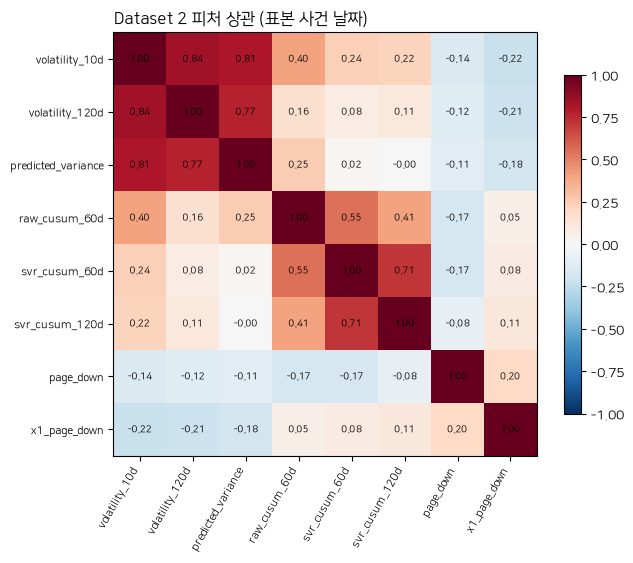

In [13]:
reasons = {  # 피처별 결측 사유 규칙
    "volatility_10d": "유효 수익률 10개 미만", "volatility_120d": "유효 수익률 120개 미만",
    "predicted_variance": "첫 적합(2018) 이전", "raw_cusum_60d": "창 유효 < 54",
    "svr_cusum_60d": "창 유효 e < 54 (2018 초 또는 σ̂²≤0)", "svr_cusum_120d": "창 유효 e < 108 (2018 상반기)",
    "page_down": "첫 유효 e 이전", "x1_page_down": "[t−252, t−61] 유효 e < 120 (2018-01 시작 후 약 181 거래일)",
}
miss = pd.DataFrame({"missing_rows": rows[FEATURES].isna().sum(), "missing_rate": rows[FEATURES].isna().mean().round(4), "first_valid_date_daily": [daily.loc[daily[f].notna(), "date"].min().date() for f in FEATURES], "reason": [reasons[f] for f in FEATURES]})  # 결측 요약
miss["skew"] = rows[FEATURES].skew().round(2)  # 왜도
print(miss)  # 출력
fig, ax = plt.subplots(figsize=(7, 5.5))  # 피처 상관 히트맵
cm = rows[FEATURES].corr().to_numpy()  # 상관 행렬
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)  # 히트맵
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)  # 눈금
for i in range(len(FEATURES)):  # 칸마다 값 표기
    for j in range(len(FEATURES)):  # 열
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7)  # 상관 값
fig.colorbar(im, ax=ax, shrink=0.8)  # 색 막대
ax.set_title("Dataset 2 피처 상관 (표본 사건 날짜)", loc="left")  # 제목
fig.savefig(FIG / "02_feature_correlation.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

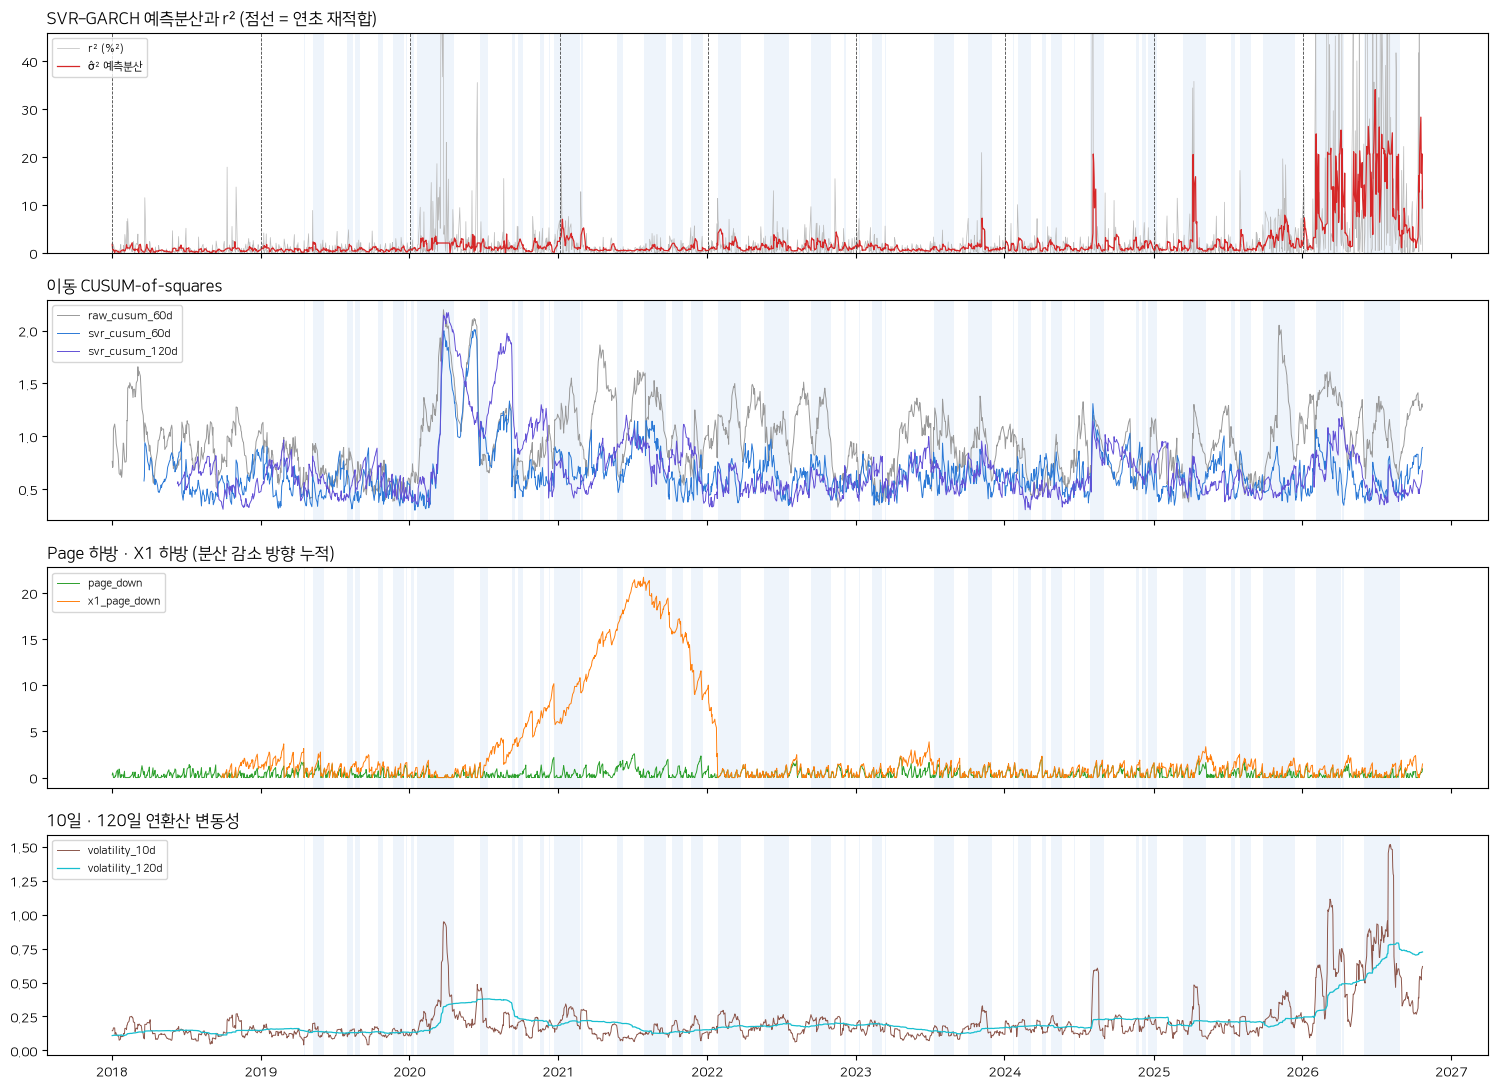

In [14]:
a = daily[daily["date"] >= pd.Timestamp("2018-01-01")]  # 2018 이후
fig, ax = plt.subplots(4, 1, figsize=(15, 11), sharex=True)  # 4단 시계열
ax[0].plot(a["date"], a["r_pct"] ** 2, color="#bbbbbb", lw=0.5, label="r² (%²)")  # 실현 제곱수익률
ax[0].plot(a["date"], a["predicted_variance"], color="#d62728", lw=0.9, label="σ̂² 예측분산")  # 예측분산
for d in fits["fit_at"]:  # 재적합 경계
    ax[0].axvline(pd.Timestamp(d), color="#444444", lw=0.6, ls="--")  # 점선
ax[0].set_ylim(0, np.nanquantile(a["r_pct"] ** 2, 0.99)); ax[0].legend(fontsize=8); ax[0].set_title("SVR–GARCH 예측분산과 r² (점선 = 연초 재적합)", loc="left")  # 꾸미기
for c, col in (("raw_cusum_60d", "#999999"), ("svr_cusum_60d", "#2a78d6"), ("svr_cusum_120d", "#6250d6")):  # 세 CUSUM
    ax[1].plot(a["date"], a[c], lw=0.7, color=col, label=c)  # 시계열
ax[1].legend(fontsize=8); ax[1].set_title("이동 CUSUM-of-squares", loc="left")  # 꾸미기
ax[2].plot(a["date"], a["page_down"], lw=0.7, color="#2ca02c", label="page_down"); ax[2].plot(a["date"], a["x1_page_down"], lw=0.7, color="#ff7f0e", label="x1_page_down")  # Page 상태
ax[2].legend(fontsize=8); ax[2].set_title("Page 하방 · X1 하방 (분산 감소 방향 누적)", loc="left")  # 꾸미기
ax[3].plot(a["date"], a["volatility_10d"], lw=0.7, color="#8c564b", label="volatility_10d"); ax[3].plot(a["date"], a["volatility_120d"], lw=0.9, color="#17becf", label="volatility_120d")  # 변동성
ax[3].legend(fontsize=8); ax[3].set_title("10일 · 120일 연환산 변동성", loc="left")  # 꾸미기
for w in main_ev.itertuples():  # 급변 사건 음영
    for k in range(4):  # 모든 패널
        ax[k].axvspan(w.start_date, w.end_date, color="#2a78d6", alpha=0.08, lw=0)  # 음영
fig.tight_layout()  # 정리
fig.savefig(FIG / "02_feature_timeseries.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

## 10. 학습·검증 분할과 표준화 — 보류 (모델 설계와 함께 결정)
분할 배정은 하지 않는다. Dataset 2 특유의 사항(초기 결측 채널 때문에 결측 없는 사건 수가 줄어드는 점)만 기록한다. 공통 의견은 Dataset 1 의 `split_manifest.json` 에 있다.

In [15]:
tr_ev = main_ev[["event_id", "start_date", "end_date", "duration_days", "analysis_year"]].copy()  # 이벤트 메타
tr_ev["crosses_year_boundary"] = tr_ev["start_date"].dt.year != tr_ev["end_date"].dt.year  # 연도 걸침
ok_cnt = rows.assign(ok=rows[REGISTERED].notna().all(axis=1)).groupby("event_id")["ok"].sum()  # 사건별 등록 피처 모두 유효한 날 수
tr_ev["n_valid_rows"] = tr_ev["event_id"].map(ok_cnt).astype(int)  # 추가
tr_ev["fully_valid"] = tr_ev["n_valid_rows"] == tr_ev["duration_days"]  # 결측 없는 사건
save_pair(tr_ev, TRAIN / "events.parquet")  # 저장
split_manifest = {"split_status": "DEFERRED_UNTIL_MODEL_DESIGN", "assignment": None, "see_also": "data/training/dataset_1/split_manifest.json (공통 의견)",
                  "dataset_2_notes": [f"등록 피처가 모두 유효한 사건 {int(tr_ev['fully_valid'].sum())}/{len(tr_ev)}개. 결측이 남은 사건은 시작 연도 {sorted(tr_ev.loc[~tr_ev['fully_valid'], 'analysis_year'].unique().tolist())}.",
                                      "SVR 은 매년 연초 재적합이므로 학습 분할 경계를 연도 경계에 두면 모형 적합과 분할이 같은 시간 규칙을 따른다.",
                                      "예측분산·CUSUM 은 연도별 척도가 다르다 — 표준화는 학습 분할에서만 적합해야 한다."],
                  "events_by_year": tr_ev.groupby("analysis_year").size().to_dict()}
save_json(split_manifest, TRAIN / "split_manifest.json")  # 저장
scaler = {"status": "NOT_FITTED", "rule": "학습 분할의 obs_mask & ~missing_mask 위치에서만 피처별 평균·표준편차 적합", "transform_candidates": {f: {"skew": float(miss.loc[f, "skew"]), "candidate": "log 또는 log1p 검토" if abs(miss.loc[f, "skew"]) > 2 else "none"} for f in FEATURES}, "descriptive_only": rows[FEATURES].describe().round(6).to_dict()}  # 규칙·근거
save_json(scaler, TRAIN / "scaler.json")  # 저장
tr_ev.groupby("analysis_year").agg(n=("event_id", "size"), fully_valid=("fully_valid", "sum"))  # 연도별 유효 사건

,n,fully_valid
analysis_year,,
2019,14,14
2020,10,10
2021,6,6
2022,5,5
2023,6,6
2024,13,13
2025,7,7
2026,3,3


## 11. 가변 길이 학습 데이터 출력
형식은 Dataset 1 과 같다. **배열에는 등록된 피처만** 넣고, 기각된 피처는 원값 표에만 남긴다.

X: (64, 63, 7) | 결측 칸: 0 / 6237 | 정상 X: (57, 61, 7)


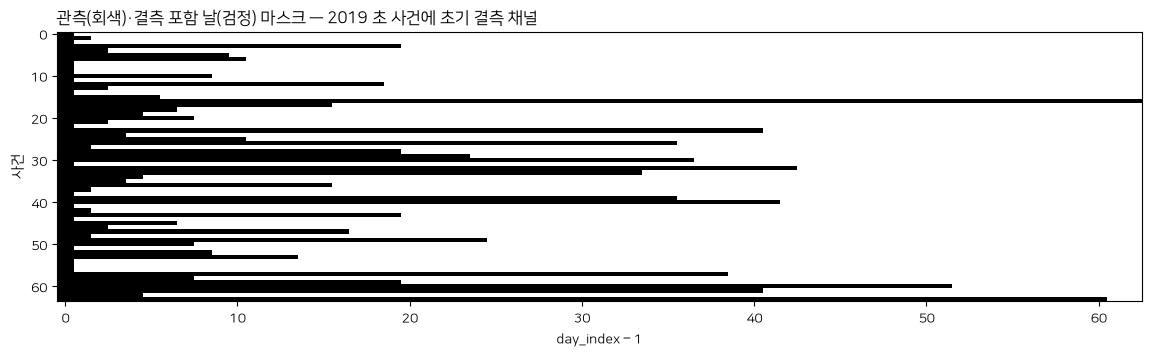

In [16]:
def to_tensor(tab: pd.DataFrame, id_col: str, feats: list):
    """하루 행 → (X, obs_mask, missing_mask, lengths, ids)."""
    ids = np.array(sorted(tab[id_col].unique()))  # ID 정렬
    groups = {k: g.sort_values("day_index") for k, g in tab.groupby(id_col)}  # 구간별
    lengths = np.array([len(groups[k]) for k in ids], dtype=np.int32)  # 길이
    X = np.zeros((len(ids), int(lengths.max()), len(feats)), dtype=np.float32)  # 값 (0 패딩)
    obs = np.zeros(X.shape[:2], dtype=bool)  # 실제 날짜
    mis = np.zeros(X.shape, dtype=bool)  # 결측
    for i, k in enumerate(ids):  # 구간마다
        v = groups[k][feats].to_numpy(dtype="float64")  # 값
        obs[i, :len(v)] = True  # 실제 날짜
        mis[i, :len(v)] = ~np.isfinite(v)  # 결측
        X[i, :len(v)] = np.where(np.isfinite(v), v, 0.0)  # 결측 → 0 (마스크로 구분)
    return X, obs, mis, lengths, ids  # 반환


X, obs, mis, lengths, ids = to_tensor(rows, "event_id", REGISTERED)  # 사건 배열
np.savez_compressed(TRAIN / "features.npz", X=X, obs_mask=obs, missing_mask=mis, lengths=lengths, event_ids=ids, feature_names=np.array(REGISTERED))  # 저장
Xn, obsn, misn, lenn, idsn = to_tensor(nrows, "ref_id", REGISTERED)  # 정상 구간
np.savez_compressed(TRAIN / "normal_reference_features.npz", X=Xn, obs_mask=obsn, missing_mask=misn, lengths=lenn, ref_ids=idsn, feature_names=np.array(REGISTERED))  # 저장
FORMULA = {"volatility_10d": "std(lr_{t-9..t}, ddof=1)*sqrt(252)", "volatility_120d": "std(lr_{t-119..t}, ddof=1)*sqrt(252)", "predicted_variance": "SVR_A(r_pct_{t-1}^2, proxy5_{t-1}), 연초 확장 재적합", "raw_cusum_60d": "CoS(r_pct, [t-59,t])", "svr_cusum_60d": "CoS(e, [t-59,t])", "svr_cusum_120d": "CoS(e, [t-119,t])", "page_down": "Page(e, lambda=0.5) free state", "x1_page_down": "Page(e/sqrt(mean e^2 [t-252,t-61]), lambda=0.5)"}  # 식
UNIT = {"volatility_10d": "연환산 소수", "volatility_120d": "연환산 소수", "predicted_variance": "%^2", "raw_cusum_60d": "무차원", "svr_cusum_60d": "무차원", "svr_cusum_120d": "무차원", "page_down": "로그우도비", "x1_page_down": "로그우도비"}  # 단위
save_json({"features": [{"index": i, "name": f, "dtype": "float32", "unit": UNIT[f], "formula": FORMULA[f], "info_time": "close_{t-1}" if f == "predicted_variance" else "close_t"} for i, f in enumerate(REGISTERED)], "rejected": REJECTED, "metadata_not_input": META, "axis_order": "X[event, day, feature]"}, TRAIN / "feature_columns.json")  # 저장
print("X:", X.shape, "| 결측 칸:", int(mis.sum()), "/", int(obs.sum()) * len(REGISTERED), "| 정상 X:", Xn.shape)  # 정보
fig, ax = plt.subplots(figsize=(14, 3.5))  # 결측 마스크 그림
ax.imshow((mis.any(axis=2) & obs).astype(int) + obs.astype(int), aspect="auto", cmap="Greys", interpolation="nearest")  # 0 패딩 · 1 관측 · 2 결측 포함
ax.set_title("관측(회색)·결측 포함 날(검정) 마스크 — 2019 초 사건에 초기 결측 채널", loc="left"); ax.set_xlabel("day_index − 1"); ax.set_ylabel("사건")  # 꾸미기
fig.savefig(FIG / "02_missing_mask.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

## 12. 품질 검증 및 재현성 검사
- **정보 시점**: 각 적합의 학습 끝 < 예측 시작인지, v̂_t 가 t−1 까지 자료만 쓰는지를 미래 자료를 바꿔 보는 격리 시험으로 확인한다.
- **정의 재검산**: 작은 예시 값으로 CUSUM·Page 를 손계산과 대조한다.

In [17]:
chk = {}  # 검사 사전
chk["svr_train_end_before_predict"] = bool((pd.to_datetime(fits["train_end"]) < pd.to_datetime(fits["predict_from"])).all())  # 적합 자료가 예측 기간보다 앞
# 격리 시험: 2022-06-30 이후 수익률을 바꿔도 그 전 v̂·CUSUM·Page 가 그대로인지
cut = int(np.flatnonzero(px["date"] >= pd.Timestamp("2022-06-30"))[0])  # 절단 위치
r2 = r.copy(); r2[cut:] *= 3.0  # 미래 값만 변경 (격리 복사본)
vh2 = np.full(len(r2), np.nan)  # 재계산 예측분산
for k, a0 in enumerate(starts):  # 같은 적합 절차
    b0 = starts[k + 1] if k + 1 < len(starts) else len(r2)  # 연도 끝
    if a0 > cut:  # 절단 이후 연도는 비교 대상이 아니므로 생략 (시간 절약)
        break  # 중단
    m2, _, _, _ = fit_svr(r2[:a0])  # a0 이전 자료만
    pc2 = proxy(r2[:b0])  # 프록시
    vh2[a0:b0] = m2.predict(np.c_[r2[a0 - 1:b0 - 1] ** 2, pc2[a0 - 1:b0 - 1]])  # 예측
chk["future_perturbation_vhat_unchanged"] = bool(np.allclose(vh2[:cut + 1], vhat[:cut + 1], equal_nan=True))  # t=cut 의 v̂ 는 cut−1 까지만 쓰므로 cut 포함 동일해야 함
e2 = np.where(vh2 > 0, r2 / np.sqrt(np.where(vh2 > 0, vh2, 1.0)), np.nan)  # 재계산 잔차
chk["future_perturbation_cusum_page_unchanged"] = bool(np.allclose(rolling_cos(e2, 60)[:cut], daily["svr_cusum_60d"].to_numpy()[:cut], equal_nan=True) and np.allclose(page_free(e2, 0.5)[:cut], daily["page_down"].to_numpy()[:cut], equal_nan=True) and np.allclose(page_free(selfnorm(e2), 0.5)[:cut], daily["x1_page_down"].to_numpy()[:cut], equal_nan=True))  # t<cut 불변
# 정의 재검산 (격리된 소규모 예시)
toy = np.array([1.0, -2.0, 0.5, 0.3, np.nan, 1.5, -0.7, 2.2, 0.1, -1.1])  # 예시 값 10개 (결측 1개 → 유효 9 ≥ ⌈0.9·10⌉)
v = toy[~np.isnan(toy)]; S = np.cumsum(v ** 2); n = len(v)  # 손계산: 유효 값, 누적 제곱합
hand = np.max(np.abs(S - np.arange(1, n + 1) / n * S[-1])) / (np.sqrt(n) * np.sqrt(np.mean(v ** 4) - np.mean(v ** 2) ** 2))  # 손계산 통계량
chk["cos_definition_toy"] = bool(np.isclose(rolling_cos(toy, 10)[-1], hand))  # 함수와 일치 (창 10)
hand_page = []; s = 0.0  # 손계산 Page
for x in toy:  # 값마다
    if np.isfinite(x):  # 유효
        s = max(0.0, s + 0.5 * ((1 - 2.0) * x ** 2 + np.log(2.0)))  # λ=0.5: (1−1/λ)=−1, −ln λ = ln 2
    hand_page.append(s)  # 기록
chk["page_definition_toy"] = bool(np.allclose(page_free(toy, 0.5), hand_page))  # 함수와 일치
chk["vol_recompute"] = bool(np.allclose(daily["volatility_10d"].iloc[200], np.std(px["lr"].iloc[191:201], ddof=1) * np.sqrt(252)) and np.allclose(daily["volatility_120d"].iloc[300], np.std(px["lr"].iloc[181:301], ddof=1) * np.sqrt(252)))  # 변동성 재계산
chk["event_alignment_with_dataset_1"] = bool(same_as_d1)  # 정렬
chk["no_inf"] = bool(np.isfinite(rows[FEATURES].to_numpy(dtype="float64")[rows[FEATURES].notna().to_numpy()]).all())  # 무한대 없음
chk["feature_count"] = {"expected": 8, "registered": len(REGISTERED), "pass": len(REGISTERED) == 8}  # 피처 수
chk["no_alarm_pvalue_vol20_inputs"] = not any(k in " ".join(REGISTERED) for k in ("alarm", "pvalue", "vol20", "vol60"))  # 금지 입력 없음
chk["missing_masked_not_zero_filled"] = bool(int(mis.sum()) == int(rows[REGISTERED].isna().sum().sum()))  # 결측 수 = 마스크 수
chk["scaler_not_fitted"] = True  # 분할 보류
for k_ in ("svr_train_end_before_predict", "future_perturbation_vhat_unchanged", "future_perturbation_cusum_page_unchanged"):  # 미래정보 계약
    assert chk[k_], f"미래정보 검사 실패: {k_}"  # 위반이면 중단
fails = [k for k, v in chk.items() if v is False or (isinstance(v, dict) and v.get("pass") is False)]  # 실패 목록
status = "TRAIN_READY" if not fails and not REJECTED else "PARTIAL"  # 기각 피처가 있으면 PARTIAL
validation = {"dataset": "dataset_2", "checks": chk, "fails": fails, "registered": REGISTERED, "rejected": REJECTED, "gate": gate.to_dict("records"), "missing": miss.reset_index(names="feature").to_dict("records"), "status": status, "split_status": "DEFERRED_UNTIL_MODEL_DESIGN"}  # 보고
save_json(validation, QUALITY / "dataset_2_validation.json")  # 저장
out_hash = {p: content_hash(pd.read_parquet(ROOT / p)) for p in ["data/processed/dataset_2/daily_features.parquet", "data/processed/dataset_2/event_rows.parquet", "data/processed/dataset_2/normal_reference.parquet", "data/training/dataset_2/events.parquet", "data/processed/dataset_2/svr_fit_log.parquet"]}  # 출력 해시
out_hash["features.npz:X"] = hashlib.sha256(X.tobytes()).hexdigest()  # 배열 해시
save_json({"dataset": "dataset_2", "status": status, "split_status": "DEFERRED_UNTIL_MODEL_DESIGN", "input_hashes": done, "versions": VERSIONS, "n_events": int(X.shape[0]), "n_fully_valid_events": int(tr_ev["fully_valid"].sum()), "tensor_shape": list(X.shape), "features": REGISTERED, "rejected": REJECTED, "svr_fits": fits.astype(str).to_dict("records"), "outputs_content_hash": out_hash, "validation_fails": fails}, TRAIN / "dataset_manifest.json")  # manifest
print(json.dumps({"status": status, "fails": fails, "rejected": REJECTED}, ensure_ascii=False))  # 결과
chk  # 검사 표

{"status": "PARTIAL", "fails": ["feature_count"], "rejected": ["page_down"]}


{'svr_train_end_before_predict': True,
 'future_perturbation_vhat_unchanged': True,
 'future_perturbation_cusum_page_unchanged': True,
 'cos_definition_toy': True,
 'page_definition_toy': True,
 'vol_recompute': True,
 'event_alignment_with_dataset_1': True,
 'no_inf': True,
 'feature_count': {'expected': 8, 'registered': 7, 'pass': False},
 'no_alarm_pvalue_vol20_inputs': True,
 'missing_masked_not_zero_filled': True,
 'scaler_not_fitted': True}

## 13. 결과 요약 및 데이터 계약
- 입력: 01 노트북 산출물 (해시 대조 통과 시에만 진행).
- 일별 피처 전체: `data/processed/dataset_2/daily_features.parquet` (메타 `model_fit_id`·`days_since_refit`·`forecast_ceiling`·`cos*_mixed_fit`·`e_std_residual` 포함 — 모델 입력 아님).
- 사건 행: `event_rows.parquet`, 정상 구간: `normal_reference.parquet`, SVR 적합 기록: `svr_fit_log.parquet`.
- 유사성 게이트: `data/quality/dataset_2_similarity_gate.parquet` — 등록된 피처만 `data/training/dataset_2/features.npz` 에 들어간다.
- 2019 초 사건은 120일 CUSUM·X1 등이 결측일 수 있다 → `missing_mask` 로 구분 (0 은 값이 아니라 패딩).
- 분할·표준화는 보류. X1 은 탐색적(EXPLORATORY) 통계량이라는 점을 학습 설계 때 함께 고려한다.